# Imports

In [1]:
from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
import re
import html
from scipy.sparse import hstack
from sklearn.preprocessing import normalize
from sentence_transformers import SentenceTransformer

C:\Users\Utilizador\anaconda3\envs\dtu02452\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Call the data

In [2]:
# Substitui pelo caminho da tua pasta
data_dir = Path(r"C:\Users\Utilizador\Downloads\books_50pct")

meta_path = data_dir / "books_50pct_users_meta.parquet"
reviews_path = data_dir / "books_50pct_users_reviews.parquet"

## See meta data

In [3]:
meta_file = pq.ParquetFile(meta_path)

# Ler apenas as primeiras 10 linhas
meta = next(meta_file.iter_batches(batch_size=10)).to_pandas()

display(meta)

,item_id,title,description,price,brand,categories
0,0001055178,Master Georgie,Beryl Bainbridge seems drawn to disaster. Firs...,16.95,,[[Books]]
1,0001473727,The Greatest Book on &quot;Dispensational Trut...,,2.99,,[[Books]]
2,000171287X,The Berenstains' B Book (Bright &amp; Early Bo...,"By Stan Berenstain and Jan Berenstain, Illustr...",3.13,,[[Books]]
3,000100039X,The Prophet,"In a distant, timeless place, a mysterious pro...",3.99,,[[Books]]
4,0001473905,Rightly Dividing the Word,--This text refers to thePaperbackedition.,2.99,,[[Books]]
5,0001714538,The Berenstain Bears on the Moon (Bright and E...,PreSchool-Grade 2 A delightful tale told in rh...,8.09,,[[Books]]
6,0001473123,The Book of Revelation,"American Baptist pastor, Bible teacher, and wr...",2.96,,[[Books]]
7,0002005395,Deafening,,9.39,,[[Books]]
8,0002051850,For Whom the Bell Tolls,,8.99,,[[Books]]
9,0002006715,Lady Franklin's Revenge A True Story of Ambiti...,,NaN,,[[Books]]


## See reviews data

In [4]:
reviews_file = pq.ParquetFile(reviews_path)

# Ler apenas as primeiras 10 linhas
reviews = next(reviews_file.iter_batches(batch_size=10)).to_pandas()

display(reviews)

,user_id,item_id,rating,summary,review_text,helpful_votes,timestamp
0,A10000012B7CGYKOMPQ4L,000100039X,5.0,Wonderful!,Spiritually and mentally inspiring! A book tha...,"[0, 0]",1355616000
1,A12387207U8U24,000100039X,5.0,Graet Work,"As you read, Gibran's poetry brings spiritual ...","[0, 0]",1206662400
2,A29TRDMK51GKZR,000100039X,5.0,Such Beauty,"Deep, moving dramatic verses of the heart and ...","[0, 0]",1383436800
3,A3FI0744PG1WYG,000100039X,5.0,The Prophet,This is a timeless classic. Over the years I'...,"[0, 0]",1390953600
4,A19N3FCQCLJYUA,000100039X,5.0,A book everyone &#34;should&#34; read,I discovered The Prophet fifty years ago in co...,"[1, 1]",1358899200
5,A1TT4CY55WLHAR,000100039X,5.0,"textured paper, old-style typography, and leat...","I have the 1972 version, bought in 1974. The 1...","[0, 0]",1342396800
6,AENNW2G826191,000100039X,3.0,Good Read,"Its a thin book, very readable and has interes...","[1, 4]",963446400
7,A1KQ80Y692CDOI,000100039X,2.0,Eloquent,I read this about a year ago and can't recall ...,"[2, 9]",1206057600
8,AUTNO7VDY4H4A,000100039X,5.0,"A great book, buying it for a friend.","Loved this book since first I read it, years g...","[0, 0]",1371427200
9,AF7CSSGV93RXN,000100039X,5.0,A Great Little Gift,I first read The Prophet by Kahlil Gibran over...,"[5, 6]",1331510400


# Explore the data

In [5]:
meta_file = pq.ParquetFile(meta_path)
reviews_file = pq.ParquetFile(reviews_path)

print("=== AMAZON BOOKS DATASET ===")

print("\nMetadata:")
print("Number of records:", f"{meta_file.metadata.num_rows:,}")

print("\nReviews:")
print("Number of records:",  f"{reviews_file.metadata.num_rows:,}")

print("\nNumber of row groups:")
print("Metadata:", meta_file.num_row_groups)
print("Reviews:", reviews_file.num_row_groups)


=== AMAZON BOOKS DATASET ===

Metadata:
Number of records: 349,741

Reviews:
Number of records: 4,408,904

Number of row groups:
Metadata: 1
Reviews: 5


In [6]:
# Initialize sets to store unique user and book IDs
unique_users = set()
unique_books = set()

# Process the reviews dataset in batches to reduce memory usage
for batch in reviews_file.iter_batches( batch_size=100_000, columns=["user_id", "item_id"]):
    df = batch.to_pandas()

    # Update the sets with unique, non-null identifiers
    unique_users.update(df["user_id"].dropna().unique())
    unique_books.update(df["item_id"].dropna().unique())

# Display dataset statistics
print("=== DATASET STATISTICS ===")
print(f"Unique users: {len(unique_users):,}")
print(f"Unique reviewed books: {len(unique_books):,}")
print(f"Total reviews: {reviews_file.metadata.num_rows:,}")

# Calculate the average number of reviews per user and book
print("\nAverage reviews per user:",
      round(reviews_file.metadata.num_rows / len(unique_users), 2)
      if unique_users else "N/A")

print("Average reviews per book:",
      round(reviews_file.metadata.num_rows / len(unique_books), 2)
      if unique_books else "N/A")

=== DATASET STATISTICS ===
Unique users: 301,553
Unique reviewed books: 349,741
Total reviews: 4,408,904

Average reviews per user: 14.62
Average reviews per book: 12.61


## Statistics 

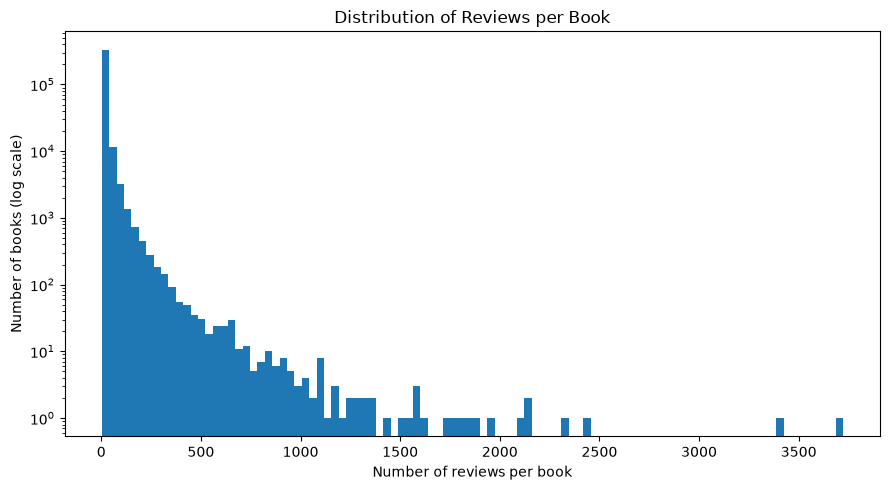

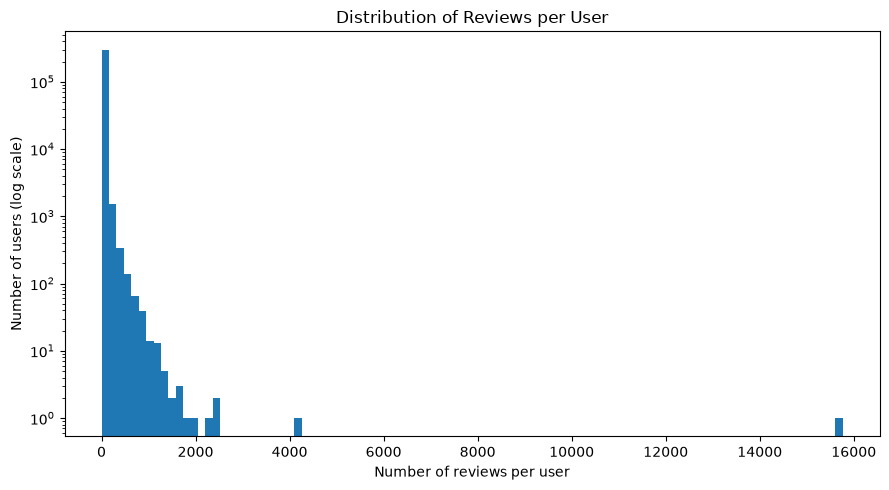

In [7]:
# Initialize counters for books and users
book_counts = Counter()
user_counts = Counter()

# Process the dataset in batches
for batch in reviews_file.iter_batches( batch_size=100_000, columns=["user_id", "item_id"]):
    df = batch.to_pandas()

    # Count reviews per book and per user
    book_counts.update(df["item_id"].dropna())
    user_counts.update(df["user_id"].dropna())

# Convert counts to arrays
reviews_per_book = list(book_counts.values())
reviews_per_user = list(user_counts.values())

# Plot the distribution of reviews per book
plt.figure(figsize=(9, 5))
plt.hist(reviews_per_book, bins=100, log=True)
plt.xlabel("Number of reviews per book")
plt.ylabel("Number of books (log scale)")
plt.title("Distribution of Reviews per Book")
plt.tight_layout()
plt.show()

# Plot the distribution of reviews per user
plt.figure(figsize=(9, 5))
plt.hist(reviews_per_user, bins=100, log=True)
plt.xlabel("Number of reviews per user")
plt.ylabel("Number of users (log scale)")
plt.title("Distribution of Reviews per User")
plt.tight_layout()
plt.show()

### First graph — Reviews per Book

Most books have relatively few reviews, while a small number reach hundreds or thousands of reviews. This is a long-tailed distribution.

### Second graph — Reviews per User

Something similar happens: most users have reviewed few books, but there are some extremely active users. One of them seems to be approaching 16,000 reviews!

In [8]:
# Summary statistics for book interactions
print("=== REVIEWS PER BOOK ===")
print("Minimum:", np.min(reviews_per_book))
print("Median:", np.median(reviews_per_book))
print("Mean:", np.mean(reviews_per_book))
print("90th percentile:", np.percentile(reviews_per_book, 90))
print("Maximum:", np.max(reviews_per_book))

# Summary statistics for user interactions
print("\n=== REVIEWS PER USER ===")
print("Minimum:", np.min(reviews_per_user))
print("Median:", np.median(reviews_per_user))
print("Mean:", np.mean(reviews_per_user))
print("90th percentile:", np.percentile(reviews_per_user, 90))
print("Maximum:", np.max(reviews_per_user))

=== REVIEWS PER BOOK ===
Minimum: 2
Median: 6.0
Mean: 12.606197157324992
90th percentile: 24.0
Maximum: 3722

=== REVIEWS PER USER ===
Minimum: 3
Median: 8.0
Mean: 14.620660381425488
90th percentile: 24.0
Maximum: 15761


### Analysis of Filtering Scenarios

The original Amazon Books dataset contains 349,741 unique books, 301,553 unique users, and 4,408,904 reviews.

Exploratory data analysis revealed a highly uneven distribution of interactions. The median number of reviews is 6 per book and 8 per user, while the maximum values reach 3,722 reviews per book and 15,761 reviews per user.

This imbalance introduces two main challenges for the recommendation system:

Books with few reviews: Limited interaction data may produce unreliable similarity estimates, particularly when similarities are based on very few common users.

Highly active users: Users who have reviewed thousands of books can generate a disproportionately large number of book-to-book connections, increasing computational complexity and potentially introducing less informative relationships.

In [9]:
# Define candidate filtering scenarios
scenarios = {
    "A - Inclusive": (5, 500),
    "B - Moderate": (10, 200),
    "C - Restrictive": (20, 100)}

results = []

# Evaluate the number of retained books and users
for scenario, (min_book_reviews, max_user_reviews) in scenarios.items():

    retained_books = sum( count >= min_book_reviews for count in book_counts.values())
    retained_users = sum( count <= max_user_reviews for count in user_counts.values())
    results.append({
        "Scenario": scenario,
        "Min Book Reviews": min_book_reviews,
        "Max User Reviews": max_user_reviews,
        "Retained Books": retained_books,
        "Retained Users": retained_users,
        "Books Retained (%)": round( 100 * retained_books / len(book_counts), 2),
        "Users Retained (%)": round(100 * retained_users / len(user_counts), 2)})

# Display scenario comparison
scenario_df = pd.DataFrame(results)
display(scenario_df)

,Scenario,Min Book Reviews,Max User Reviews,Retained Books,Retained Users,Books Retained (%),Users Retained (%)
0,A - Inclusive,5,500,212476,301293,60.75,99.91
1,B - Moderate,10,200,102830,300101,29.40,99.52
2,C - Restrictive,20,100,46111,297163,13.18,98.54


The results indicate that the minimum number of reviews required per book has a substantially greater impact on dataset size than excluding highly active users.

Scenario A preserves a larger proportion of the book catalogue but includes books with relatively limited interaction information. Scenario C substantially reduces the number of books, potentially improving computational efficiency at the expense of catalogue coverage.

Scenario B is proposed as an initial candidate, offering a compromise between interaction information per book and catalogue coverage.

However, these results were obtained by evaluating book and user thresholds independently using the original interaction counts. They do not yet represent the number of interactions retained after applying both filters simultaneously.

Further analysis is therefore required to evaluate the combined filtering effects, the resulting interaction matrix sparsity, and the number of shared users between books before selecting the final configuration for similarity computation and graph construction.

# Book Similarity

## 1. Some functions

In [49]:
def clean_text(value):
    """Clean text while preserving useful information."""
    if not isinstance(value, str):
        return ""

    value = html.unescape(value)
    value = re.sub(r"<[^>]+>", " ", value)
    value = re.sub(r"\s+", " ", value)

    return value.strip()


def extract_categories(category_paths):
    """Extract informative categories from nested category paths."""
    generic = {"books", "kindle store", "kindle ebooks"}

    if category_paths is None:
        return set()

    if isinstance(category_paths, str):
        category_paths = [category_paths]

    categories = set()

    try:
        for path in category_paths:
            if isinstance(path, str):
                path = [path]

            for category in path:
                if isinstance(category, str):
                    category = category.strip().lower()

                    if category and category not in generic:
                        categories.add(category)

    except (TypeError, ValueError):
        return set()

    return categories


def prepare_books(books_df):
    """Prepare book metadata without excluding missing descriptions."""
    data = ( books_df .dropna(subset=["item_id"]) .drop_duplicates("item_id") .reset_index(drop=True) .copy())
    data["category_set"] = data["categories"].apply(extract_categories)
    data["clean_description"] = data["description"].apply(clean_text)

    return data


def build_similarity_model(books_df):
    """Build semantic embeddings and a category index."""
    data = prepare_books(books_df)

    print("Loading semantic model...")

    encoder = SentenceTransformer("all-MiniLM-L6-v2")

    print("Encoding book descriptions...")

    embeddings = encoder.encode( data["clean_description"].tolist(), batch_size=32, show_progress_bar=True, normalize_embeddings=True, convert_to_numpy=True)
    embeddings = embeddings.astype(np.float32)

    # Build an index for category-based retrieval
    category_index = {}

    for index, category_set in enumerate(data["category_set"]):
        for category in category_set:
            category_index.setdefault(category, []).append(index)

    return {  "books": data, "embeddings": embeddings, "category_index": category_index, "id_to_index": { book_id: i for i, book_id in enumerate(data["item_id"])}}




def recommend_books(book_id, model, top_n=10):
    data = model["books"]
    id_to_index = model["id_to_index"]
    embeddings = model["embeddings"]

    if book_id not in id_to_index:
        raise ValueError("Book not found in the model.")

    target_index = id_to_index[book_id]

    # Compute cosine similarity between book descriptions
    semantic_scores = embeddings @ embeddings[target_index]

    # Keep only books with valid titles and descriptions
    has_title = data["title"].fillna("").str.strip().ne("").to_numpy()
    has_description = data["clean_description"].str.len().gt(0).to_numpy()

    valid = has_title & has_description
    valid[target_index] = False

    # Rank books by cosine similarity
    candidates = np.flatnonzero(valid)
    order = np.argsort(semantic_scores[candidates])[::-1][:top_n]
    selected = candidates[order]

    results = data.loc[selected, ["item_id", "title"]].copy()
    results["cosine_similarity"] = semantic_scores[selected]

    return results.reset_index(drop=True)


## 2. Model

In [46]:
# Load book metadata
books = pq.read_table(
    meta_path,
    columns=["item_id", "title", "description", "categories"]
).to_pandas()

# Select a random sample of 5,000 books
books_sample = books.sample(
    n=5000,
    random_state=42
).copy()

# Add specific books for testing
test_ids = [
    "0375831002",  # The Book Thief
    "000651099X"   # Replace with Master Georgie's actual item_id if different
]

test_books = books[books["item_id"].isin(test_ids)]

books_sample = pd.concat(
    [books_sample, test_books],
    ignore_index=True
).drop_duplicates(subset="item_id")

# Check category coverage
category_count = books_sample["categories"].apply(
    lambda x: len(extract_categories(x)) > 0
).sum()

print("Books with informative categories:", category_count)

# Build semantic similarity model
model = build_similarity_model(books_sample)

print("Semantic model ready!")
print("Books indexed:", len(model["books"]))

Books with informative categories: 1098
Loading semantic model...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3630.15it/s]


Encoding book descriptions...


Batches: 100%|██████████| 157/157 [02:59<00:00,  1.14s/it]


Semantic model ready!
Books indexed: 5001


## 3.Testing

In [47]:
# Test recommendations for 20 different books

# Select books with available titles and descriptions
test_books = model["books"].loc[ model["books"]["title"].fillna("").str.strip().ne("") & model["books"]["clean_description"].str.len().gt(100)]

# Randomly select 20 books
test_books = test_books.sample( n=min(20, len(test_books)), random_state=42)

# Generate recommendations for each book
for i, (_, book) in enumerate(test_books.iterrows(), start=1):

    print(f"\n{'=' * 70}")
    print(f"TEST {i}/20")
    print(f"Selected book: {book['title']}")
    print(f"Categories: {book['category_set']}")
    print(f"{'=' * 70}")

    recommendations = recommend_books( book_id=book["item_id"], model=model, top_n=5)
    display(recommendations)



TEST 1/20
Selected book: If I Built a House
Categories: set()


,item_id,title,category_similarity,semantic_similarity,final_similarity
0,0984325654,A Dog Named Slugger,NaN,0.433783,0.433783
1,1599988348,Reading Between the Lines,NaN,0.424905,0.424905
2,0764205625,The Alarmists,NaN,0.418968,0.418968
3,1416955658,Alphabet (Paula Wiseman Books),NaN,0.417081,0.417081
4,1442413174,Thirst No. 3: The Eternal Dawn,NaN,0.411749,0.411749



TEST 2/20
Selected book: Caleb + Kate
Categories: set()


,item_id,title,category_similarity,semantic_similarity,final_similarity
0,0373250207,Fishbowl,NaN,0.558340,0.558340
1,0800719891,The Lesson: A Novel (Stoney Ridge Seasons) (Vo...,NaN,0.557111,0.557111
2,0399145079,Local Girls,NaN,0.553197,0.553197
3,0373294042,The Chivalrous Rake,NaN,0.532075,0.532075
4,1402270488,Love on a Midsummer Night,NaN,0.531876,0.531876



TEST 3/20
Selected book: Solstice: A Novel
Categories: set()


,item_id,title,category_similarity,semantic_similarity,final_similarity
0,0345327225,"Mister God, This Is Anna",NaN,0.517308,0.517308
1,0979824400,Into The Spell,NaN,0.509870,0.509870
2,0345314867,The Summer of Katya,NaN,0.507650,0.507650
3,1933836326,Your Magic or Mine? (Magic series),NaN,0.506697,0.506697
4,1846271401,The Telling,NaN,0.497170,0.497170


... (30 outputs left out)


TEST 19/20
Selected book: Elia Kazan: A Biography
Categories: set()


,item_id,title,category_similarity,semantic_similarity,final_similarity
0,0786713992,In the Moment: My Life as an Actor,NaN,0.499199,0.499199
1,0547076592,Sources of Light,NaN,0.390286,0.390286
2,0878467017,Art Czar: The Rise and Fall of Clement Greenberg,NaN,0.387097,0.387097
3,0813123607,The Lost One: A Life of Peter Lorre,NaN,0.385097,0.385097
4,1557046107,Eternal Sunshine of the Spotless Mind: The Sho...,NaN,0.381511,0.381511



TEST 20/20
Selected book: Spartacus: Rebellion
Categories: set()


,item_id,title,category_similarity,semantic_similarity,final_similarity
0,0991534212,American Sons: The Untold Story of the Falcon ...,NaN,0.435707,0.435707
1,1478230827,It's Always Darkest: a Paul Mallory thriller,NaN,0.433495,0.433495
2,1402726007,The Adventures of Huckleberry Finn (Sterling U...,NaN,0.431580,0.431580
3,0345435915,"Technokill (Starfist, Book 5)",NaN,0.429365,0.429365
4,1611098947,A Private Little War,NaN,0.417340,0.417340


In [48]:
# Find a book suitable for testing Jaccard similarity

data = model["books"]

valid = (
    data["title"].fillna("").str.strip().ne("")
    & data["clean_description"].str.len().gt(0)
)

candidates = data[
    valid & data["category_set"].map(bool)
]

best_book = None
best_matches = -1

for _, book in candidates.iterrows():
    matches = sum(
        bool(book["category_set"] & categories)
        for categories in data.loc[valid, "category_set"]
    ) - 1

    if matches > best_matches:
        best_matches = matches
        best_book = book

if best_book is not None:
    print("Selected book:", best_book["title"])
    print("Categories:", best_book["category_set"])
    print("Valid books sharing categories:", best_matches)

    display(recommend_books(best_book["item_id"], model, top_n=10))
else:
    print("No suitable book found.")

Selected book: Alaskan Travels: Far Flung Tales of Love and Adventure
Categories: {'pacific', 'travel', 'united states', 'west'}
Valid books sharing categories: 0


,item_id,title,category_similarity,semantic_similarity,final_similarity
0,1556439091,True North: A Journey into Unexplored Wilderness,NaN,0.565165,0.565165
1,1416586989,My River Chronicles: Rediscovering the Work th...,NaN,0.482672,0.482672
2,0785126619,Orson Scott Card's Wyrms,NaN,0.477434,0.477434
3,0970795718,Visions of America: Photographing Democracy,NaN,0.474552,0.474552
4,0981595936,Dark Currents,NaN,0.473316,0.473316
5,0800733614,Joy Takes Flight: A Novel (Alaskan Skies),NaN,0.470021,0.470021
6,0373885679,The Wolf Prince,NaN,0.465895,0.465895
7,1592579450,The Complete Idiot's Guide to Self-Sufficient ...,NaN,0.465436,0.465436
8,0615677738,Life Happens: More Stuff From the Sloss Holler...,NaN,0.462151,0.462151
9,0970687303,Yellowstone Treasures: The Traveler's Companio...,NaN,0.455284,0.455284
